# Titanic Survival Analysis — Exploratory Data Analysis

**Goal:** explore the Titanic passenger dataset (891 records) and find which factors were most strongly linked to survival.

**Questions I wanted to answer:**
1. What was the overall survival rate?
2. Did gender affect survival?
3. Did ticket class (a proxy for socio-economic status) affect survival?
4. Did passengers who paid higher fares survive more often?
5. Did age affect survival?

**Tools:** Python, Pandas, Matplotlib, Seaborn

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("data/titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. First look at the data

In [2]:
print("Shape:", df.shape)
print()
print("Missing values per column:")
print(df.isna().sum())
print()
print("Cabin missing %:", round(df['Cabin'].isna().mean() * 100, 1))

Shape: (891, 12)

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Cabin missing %: 77.1


## 2. Data cleaning

Cleaning steps (kept simple and documented so the analysis is reproducible):

- **Cabin** — about 77% of values are missing, so the column is dropped; there is not enough data to fill it sensibly.
- **Age** — 177 missing values filled with the **median** age (median is safer than the mean here because age has outliers).
- **Embarked** — only 2 missing values, filled with the most common port (`S`).
- **Fare** — 1 missing value in the full dataset check, filled with the median fare if present.

In [3]:
df = df.drop(columns=["Cabin"])

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
if df["Fare"].isna().any():
    df["Fare"] = df["Fare"].fillna(df["Fare"].median())

print("Missing values after cleaning:")
print(df.isna().sum().sum(), "total missing")
df.head(3)

Missing values after cleaning:
0 total missing


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S


## 3. Exploratory analysis

### Chart 1 — Overall survival rate

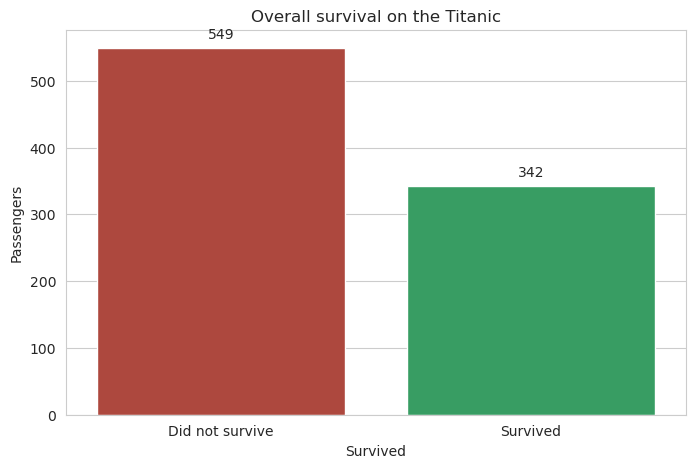

Overall survival rate: 38.4%


In [4]:
plt.figure()
ax = sns.countplot(data=df, x="Survived", hue="Survived", legend=False,
                   palette=["#c0392b", "#27ae60"])
plt.xticks([0, 1], ["Did not survive", "Survived"])
plt.ylabel("Passengers")
plt.title("Overall survival on the Titanic")
for i, v in enumerate(df["Survived"].value_counts()):
    ax.text(i, v + 15, str(v), ha="center")
plt.show()

print(f"Overall survival rate: {df['Survived'].mean() * 100:.1f}%")

**Insight:** Only about **38%** of passengers survived — roughly 1 in 3. The rest of the analysis looks at *who* was in that lucky third.

### Chart 2 — Survival by gender

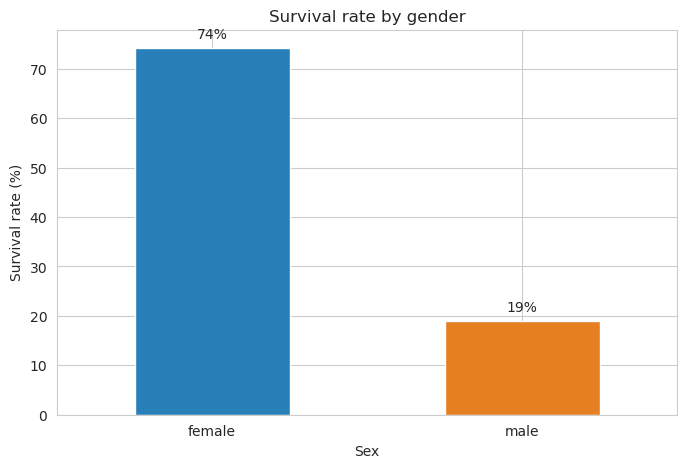

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64


In [5]:
gender_rate = df.groupby("Sex")["Survived"].mean() * 100

ax = gender_rate.plot(kind="bar", color=["#2980b9", "#e67e22"])
plt.xticks(rotation=0)
plt.ylabel("Survival rate (%)")
plt.title("Survival rate by gender")
for i, v in enumerate(gender_rate):
    ax.text(i, v + 2, f"{v:.0f}%", ha="center")
plt.show()

print(gender_rate.round(1))

**Insight:** Gender is the single strongest factor in this dataset. About **74% of women survived, compared with only 19% of men** — consistent with the "women and children first" evacuation policy.

### Chart 3 — Survival by ticket class

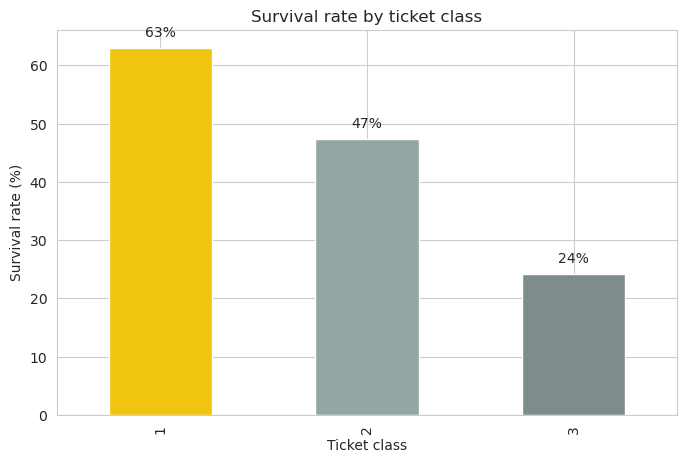

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


In [6]:
class_rate = df.groupby("Pclass")["Survived"].mean() * 100

ax = class_rate.plot(kind="bar", color=["#f1c40f", "#95a5a6", "#7f8c8d"])
plt.xlabel("Ticket class")
plt.ylabel("Survival rate (%)")
plt.title("Survival rate by ticket class")
for i, v in enumerate(class_rate):
    ax.text(i, v + 2, f"{v:.0f}%", ha="center")
plt.show()

print(class_rate.round(1))

**Insight:** Ticket class mattered a lot. **1st class passengers survived at ~63%**, 2nd class at ~47%, and **3rd class at only ~24%** — likely a mix of cabin location (higher decks, closer to lifeboats) and wealth.

### Chart 4 — Fare paid vs survival

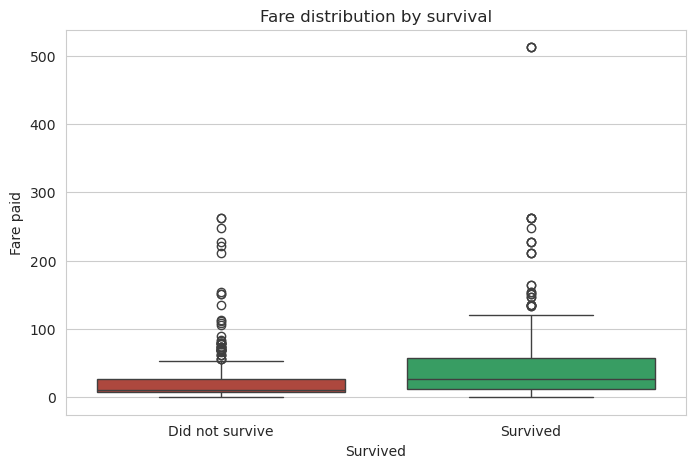

Median fare — did not survive: 10.5
Median fare — survived:       26.0


In [7]:
plt.figure()
sns.boxplot(data=df, x="Survived", y="Fare", hue="Survived", legend=False, palette=["#c0392b", "#27ae60"])
plt.xticks([0, 1], ["Did not survive", "Survived"])
plt.ylabel("Fare paid")
plt.title("Fare distribution by survival")
plt.show()

print("Median fare — did not survive:", round(df[df['Survived'] == 0]['Fare'].median(), 2))
print("Median fare — survived:      ", round(df[df['Survived'] == 1]['Fare'].median(), 2))

**Insight:** Survivors typically paid much higher fares (median roughly double that of non-survivors). Fare and class tell a similar story — both reflect where a passenger was on the ship and their socio-economic status.

### Chart 5 — Age distribution by survival

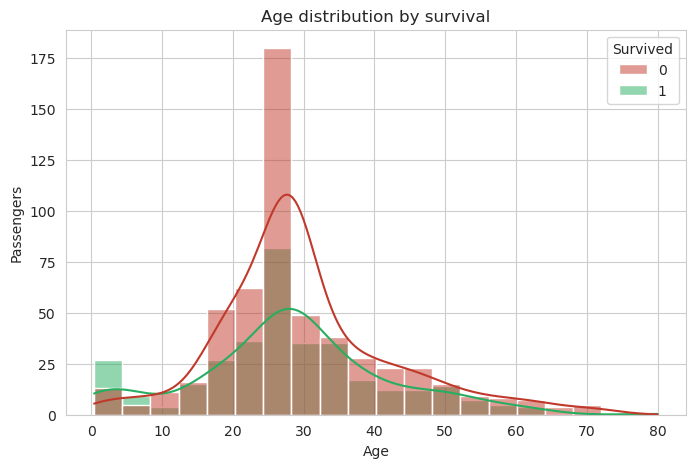

Survival rate, children (under 12): 57.4 %
Survival rate, adults (18-60):       36.5 %


In [8]:
plt.figure()
sns.histplot(data=df, x="Age", hue="Survived", bins=20, kde=True,
             palette=["#c0392b", "#27ae60"])
plt.xlabel("Age")
plt.ylabel("Passengers")
plt.title("Age distribution by survival")
plt.show()

print("Survival rate, children (under 12):",
      round(df[df['Age'] < 12]['Survived'].mean() * 100, 1), "%")
print("Survival rate, adults (18-60):      ",
      round(df[(df['Age'] >= 18) & (df['Age'] <= 60)]['Survived'].mean() * 100, 1), "%")

**Insight:** Young children show a visible survival advantage (the left peak of the green distribution), which again matches "women and children first". For adults, the age distributions of survivors and non-survivors overlap much more — age alone was a weaker factor than gender or class.

## 4. Conclusion

- Overall survival was low: **~38%**.
- **Gender** was the strongest single factor: women survived at ~74% vs ~19% for men.
- **Ticket class** was the second clear pattern: ~63% survival in 1st class vs ~24% in 3rd class, and survivors had paid notably higher fares.
- **Age** mattered mainly for young children, who were prioritised.

**Limitations:** this is exploratory analysis of one historical dataset — it shows association, not proof of cause, and fare/class/gender are correlated with each other. A natural next step is a logistic-regression model to measure each factor's effect while controlling for the others.